# Greeks and hedging

Monte Carlo Greeks with common random numbers, the Greeks of a vanilla against the spot, a delta hedge simulated through time, and the order of the Taylor P&L explain.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
BLUE, GREEN, RED, ORANGE, GREY = "#1f4e79", "#1a9850", "#d73027", "#f46d43", "#7f7f7f"
FIGURES = "../docs/figures"

 Delta: +11.5970 ± 0.8363 with common random numbers; noise 1.7x larger without
 Gamma: -0.7919 ± 0.2798 with common random numbers; noise 2.2x larger without
  Vega: -0.3073 ± 0.0146 with common random numbers; noise 3.0x larger without
   Rho: -0.0021 ± 0.0024 with common random numbers; noise 18.2x larger without


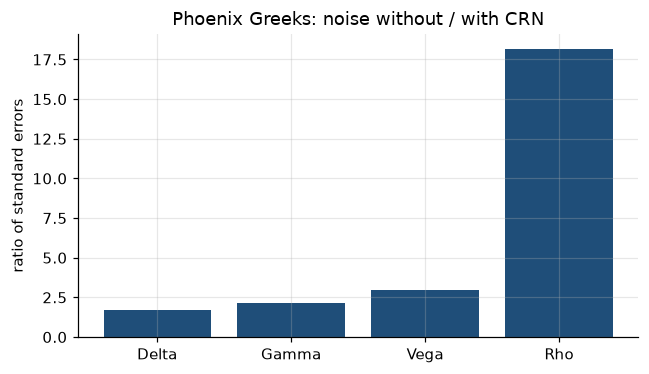

In [2]:
from spricer import strategies as strat
from spricer.hedging import derman_kamal_std, simulate_delta_hedge
from spricer.market import Basket, FlatVol, Market
from spricer.market.defaults import default_market
from spricer.mc.greeks import coupon_note_greeks
from spricer.products.coupon_notes import phoenix
from spricer.risk import residual_order

market = default_market()
note = phoenix(maturity=2.0, frequency=4, coupon_pa=8.0)
basket = Basket.single(market)
crn = coupon_note_greeks(note, basket, n_paths=50_000, seed=3)
independent = coupon_note_greeks(note, basket, n_paths=50_000, seed=3, common_random_numbers=False)
names = ["Delta", "Gamma", "Vega", "Rho"]


def pick(g):
    return [g.assets[0].delta, g.assets[0].gamma, g.assets[0].vega, g.rho]


ratios = [b.std_error / a.std_error for a, b in zip(pick(crn), pick(independent), strict=True)]
for n, a, r in zip(names, pick(crn), ratios, strict=True):
    print(
        f"{n:>6}: {a.value:+.4f} ± {a.std_error:.4f} with common random numbers; "
        f"noise {r:.1f}x larger without"
    )
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(names, ratios, color=BLUE)
ax.set(title="Phoenix Greeks: noise without / with CRN", ylabel="ratio of standard errors")
fig.tight_layout()
fig.savefig(f"{FIGURES}/crn_noise.png")

## How big a spot bump?

Structured payoffs jump at their barriers: with common random numbers only the paths crossing a jump between the two bumps contribute, so a small bump is unbiased but noisy. A barrier reverse convertible has a closed form to measure both effects (flat volatility, 100,000 paths).

In [3]:
from spricer.products.coupon_notes import barrier_reverse_convertible

brc = barrier_reverse_convertible(maturity=1.0, frequency=4, coupon_pa=6.0, barrier=70.0)
bricks = brc.replication(100.0)
flat_vol = Market(100.0, 0.03, 0.02, FlatVol(0.22))


def closed(h):
    v = [float(bricks.value(flat_vol.with_spot(100.0 * (1 + x)))) for x in (h, 0.0, -h)]
    return 0.01 * (v[0] - 2 * v[1] + v[2]) / h**2


exact = closed(1e-3)
for h in (0.01, 0.03, 0.05):
    g = (
        coupon_note_greeks(
            brc, Basket.single(flat_vol), n_paths=100_000, seed=1, delta_bump=h, gamma_bump=h
        )
        .assets[0]
        .gamma
    )
    print(
        f"bump {100 * h:.0f} %: gamma {g.value:+.3f} ± {g.std_error:.3f} "
        f"(noise {100 * g.std_error / abs(exact):.0f} %, bias of the bump "
        f"{100 * (closed(h) - exact) / abs(exact):+.1f} %), exact {exact:+.3f}"
    )

bump 1 %: gamma -2.160 ± 0.945 (noise 58 %, bias of the bump -0.0 %), exact -1.636
bump 3 %: gamma -1.815 ± 0.185 (noise 11 %, bias of the bump -0.2 %), exact -1.636


bump 5 %: gamma -1.816 ± 0.087 (noise 5 %, bias of the bump -0.7 %), exact -1.636


## Delta hedging: realised against implied volatility

 52 rebalancings: mean -0.000 ± 0.009, std 0.930 ± 0.009 (Derman-Kamal 0.952)


252 rebalancings: mean -0.004 ± 0.004, std 0.424 ± 0.004 (Derman-Kamal 0.432)


realised 25 % vs implied 20 %: mean 1.930 ± 0.010, Black-Scholes price gap 1.935


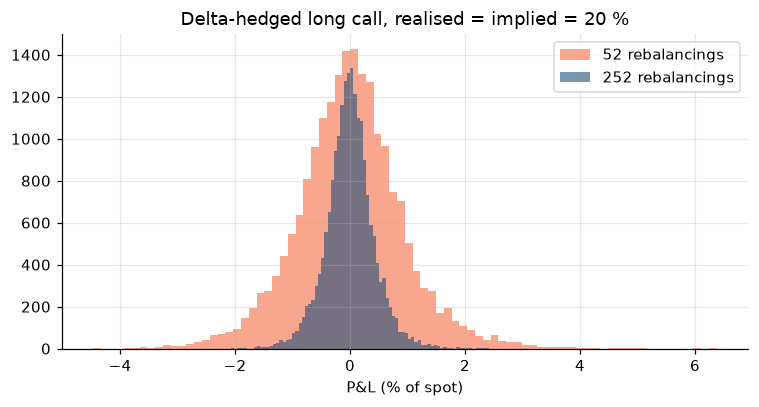

In [4]:
flat = Market(100.0, 0.03, 0.01, FlatVol(0.20))


def call(t):
    return strat.call(100.0, t)


vega = 100 * float(call(1.0).greeks(flat).vega) / 100.0
fig, ax = plt.subplots(figsize=(7, 3.8))
for n, color in ((52, ORANGE), (252, BLUE)):
    sim = simulate_delta_hedge(call, flat, 1.0, realised_vol=0.20, rebalancings=n, n_paths=20_000)
    ax.hist(sim.pnl, bins=80, alpha=0.6, color=color, label=f"{n} rebalancings")
    # Standard error of the std on independent antithetic pairs, by the delta method.
    half = len(sim.pnl) // 2
    squares = (sim.pnl - sim.pnl.mean()) ** 2
    pairs = (squares[:half] + squares[half:]) / 2
    std_error = pairs.std(ddof=1) / math.sqrt(half) / (2 * sim.std)
    print(
        f"{n:>3} rebalancings: mean {sim.mean.value:+.3f} ± {sim.mean.std_error:.3f}, "
        f"std {sim.std:.3f} ± {std_error:.3f} "
        f"(Derman-Kamal {derman_kamal_std(vega, 0.20, n):.3f})"
    )
ax.set(title="Delta-hedged long call, realised = implied = 20 %", xlabel="P&L (% of spot)")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIGURES}/hedging_pnl.png")
other = Market(100.0, 0.03, 0.01, FlatVol(0.25))
gap = float(call(1.0).value(other)) - float(call(1.0).value(flat))
sim = simulate_delta_hedge(call, flat, 1.0, realised_vol=0.25, rebalancings=252, n_paths=20_000)
print(
    f"realised 25 % vs implied 20 %: mean {sim.mean.value:.3f} ± {sim.mean.std_error:.3f}, "
    f"Black-Scholes price gap {gap:.3f}"
)

## The Taylor residual is third order

log-log slope of the residual against the move: 3.22


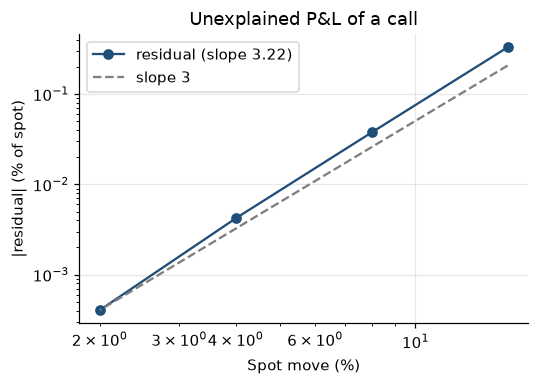

In [5]:
def value(m, t):
    return float(call(t).value(m))


# the Greeks are central differences with 1 % bumps: a 1 % move is matched exactly
moves = np.array([16.0, 8.0, 4.0, 2.0])
res = np.abs(residual_order(value, flat, 1.0, moves))
slope = np.polyfit(np.log(moves), np.log(res), 1)[0]
print(f"log-log slope of the residual against the move: {slope:.2f}")
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.loglog(moves, res, "o-", color=BLUE, label=f"residual (slope {slope:.2f})")
ax.loglog(moves, res[-1] * (moves / moves[-1]) ** 3, "--", color=GREY, label="slope 3")
ax.set(title="Unexplained P&L of a call", xlabel="Spot move (%)", ylabel="|residual| (% of spot)")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIGURES}/taylor_residual.png")